In [9]:
import matplotlib.cm as cm
import matplotlib.colors as colors
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib as mpl
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path
from scipy.stats import mannwhitneyu

In [3]:
tmp_data_save_path = '/home/nuo/Documents/data/LeciLab/behavioral_data/tmp/escape/processing_data'
sound_type = ["pink_noise", "looming"]

In [8]:
pn_leaveSpd_escape_sound_list = pd.read_csv(Path(tmp_data_save_path, f"{sound_type[0]}_sound_escape_leave_speed.csv")).values
lm_leaveSpd_escape_sound_list = pd.read_csv(Path(tmp_data_save_path, f"{sound_type[1]}_sound_escape_leave_speed.csv")).values

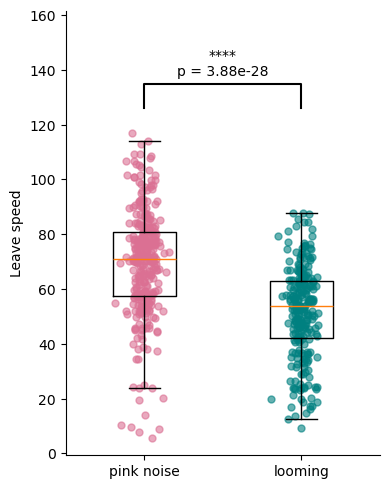

In [15]:


_pn = np.asarray(pn_leaveSpd_escape_sound_list, dtype=float)
_lm = np.asarray(lm_leaveSpd_escape_sound_list, dtype=float)

# 去掉缺失值和无穷值
_pn = _pn[np.isfinite(_pn)]
_lm = _lm[np.isfinite(_lm)]


# 双侧检验
_p = mannwhitneyu(_pn, _lm, alternative="two-sided").pvalue
_stars = "*" * sum(_p < t for t in [0.05, 0.01, 0.001, 0.0001]) or "ns"

_fig, _ax = plt.subplots(figsize=(4, 5))
_ax.boxplot([_pn, _lm], widths=0.4, showfliers=False)

# 叠加每个样本的散点
_rng = np.random.default_rng(0)
for _i, _values, _color in [
    (1, _pn, "palevioletred"),
    (2, _lm, "teal"),
]:
    _ax.scatter(
        _rng.normal(_i, 0.05, len(_values)),
        _values,
        color=_color,
        alpha=0.6,
        s=25,
    )

# 显著性括号
_h = max(np.ptp(np.r_[_pn, _lm]), 1) * 0.08
_y = max(_pn.max(), _lm.max()) + _h

_ax.plot(
    [1, 1, 2, 2],
    [_y, _y + _h, _y + _h, _y],
    color="k",
)
_ax.text(
    1.5, _y + 1.2 * _h,
    f"{_stars}\np = {_p:.3g}",
    ha="center",
    va="bottom",
)

_ax.set_xticks([1, 2], ["pink noise", "looming"])
_ax.set_ylabel("Leave speed")
_ax.set_ylim(top=_y + 4 * _h)
_ax.spines[["top", "right"]].set_visible(False)

_fig.tight_layout()
plt.show()